# 01 EDA: no-show drivers
**All data is synthetic.** Logic lives in `src/eda.py`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 200)
from src import eda

In [2]:
out = eda.run()
print(f"{out['df_rows']:,} resolved appointments; overall no-show {out['overall']:.1%}")

80,966 resolved appointments; overall no-show 22.1%


## Test results (Holm-adjusted across all tests)

In [3]:
cols = ['family','variable','effect_name','effect','n','p_holm','v_one_per_patient']
out['tests'][cols].round(4)

,family,variable,effect_name,effect,n,p_holm,v_one_per_patient
0,chi-square,Lead time (days),cramers_v,0.1224,80966,0.0,0.1340
1,chi-square,Payer,cramers_v,0.1186,80966,0.0,0.1145
2,chi-square,Modality,cramers_v,0.0663,80966,0.0,0.0757
3,chi-square,Day of week,cramers_v,0.0274,80966,0.0,0.0406
4,chi-square,Age band,cramers_v,0.0546,80966,0.0,0.0534
5,chi-square,Prior no-shows,cramers_v,0.1646,80966,0.0,0.1704
6,chi-square,Acuity,cramers_v,0.0968,80966,0.0,0.0833
7,chi-square,Appointment hour,cramers_v,0.0241,80966,0.0,0.0000
8,chi-square,Medicaid x in-person x lead>21d,cramers_v,0.1401,80966,0.0,0.1675
9,mann-whitney,Lead time (days),rank_biserial,0.1488,80966,0.0,NaN


## No-show rate by driver

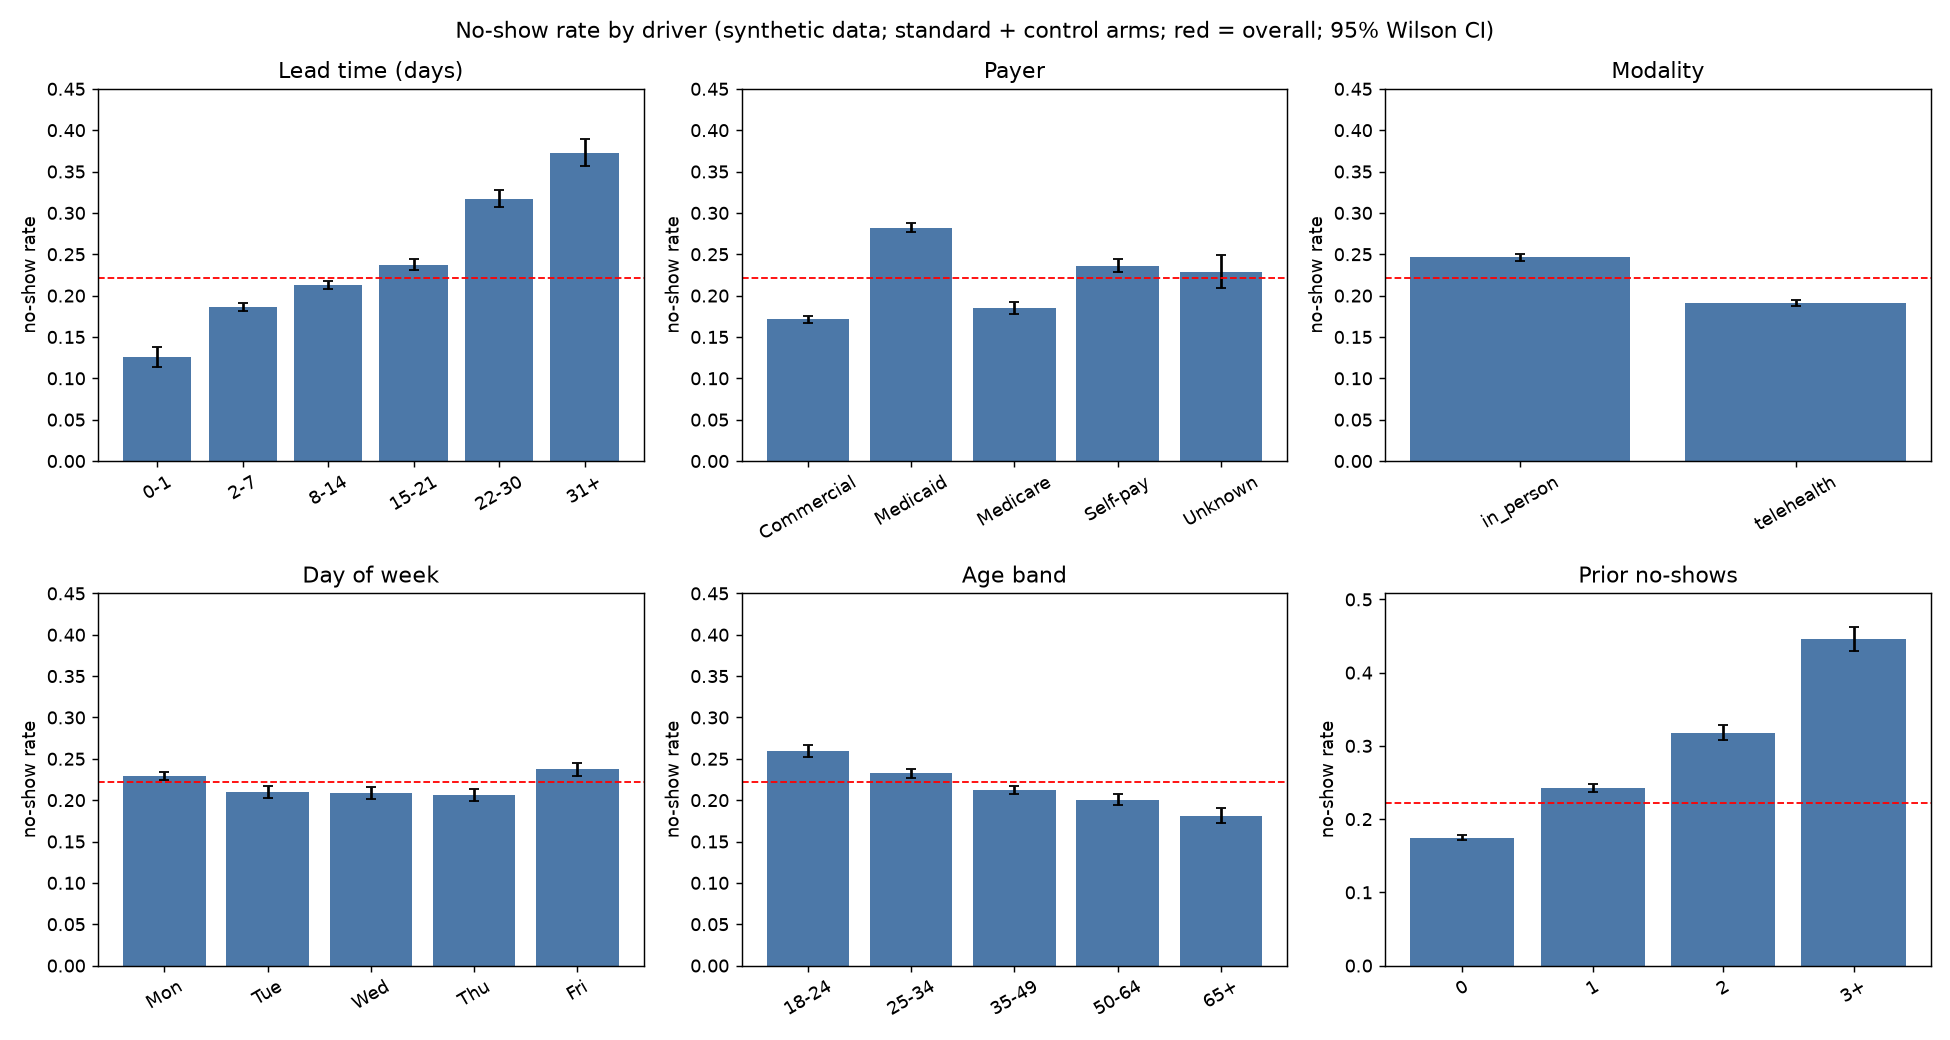

In [4]:
Image(filename=str(eda.FIGURES / 'eda_noshow_drivers.png'))

## Rates behind the figure

In [5]:
out['rates'].round(4)

,dimension,level,n,no_shows,rate,ci_low,ci_high
0,lead_bucket,0-1,2777,348,0.1253,0.1135,0.1381
1,lead_bucket,2-7,27060,5043,0.1864,0.1818,0.1910
2,lead_bucket,8-14,26644,5675,0.2130,0.2081,0.2180
3,lead_bucket,15-21,13845,3288,0.2375,0.2305,0.2446
4,lead_bucket,22-30,7155,2270,0.3173,0.3066,0.3281
5,lead_bucket,31+,3485,1299,0.3727,0.3568,0.3889
6,payer_type,Commercial,30664,5259,0.1715,0.1673,0.1758
7,payer_type,Medicaid,28350,8002,0.2823,0.2770,0.2875
8,payer_type,Medicare,9996,1849,0.1850,0.1775,0.1927
9,payer_type,Self-pay,10284,2431,0.2364,0.2283,0.2447


## Findings

In [6]:
Markdown(out['findings'])

# EDA Findings (plain language)

> ALL DATA IS SYNTHETIC. Several drivers below were PLANTED by src/generate_data.py, so this demonstrates the method; it is not evidence about real patients.

Population: 80,966 resolved appointments (completed, no-show, late-cancel) in the standard and control reminder arms. Overall no-show rate: 22.1%. Holm correction applied across all 17 tests in this script.

## Association with no-show (chi-square + Cramer's V)

- **Prior no-shows**: no-show ranges from 17.5% (0) to 44.6% (3+). Cramer's V = 0.165 (modest); Holm p = <1e-300. One-appointment-per-patient check: V = 0.170.
- **Medicaid x in-person x lead>21d**: no-show ranges from 21.2% (other) to 58.3% (cell). Cramer's V = 0.140 (modest); Holm p = <1e-300. One-appointment-per-patient check: V = 0.167.
- **Lead time (days)**: no-show ranges from 12.5% (0-1) to 37.3% (31+). Cramer's V = 0.122 (modest); Holm p = 5.52e-260. One-appointment-per-patient check: V = 0.134.
- **Payer**: no-show ranges from 17.2% (Commercial) to 28.2% (Medicaid). Cramer's V = 0.119 (modest); Holm p = 4.53e-245. One-appointment-per-patient check: V = 0.114.
- **Acuity**: no-show ranges from 18.2% (low) to 32.7% (high). Cramer's V = 0.097 (weak); Holm p = 2.69e-165. One-appointment-per-patient check: V = 0.083.
- **Modality**: no-show ranges from 19.1% (telehealth) to 24.6% (in_person). Cramer's V = 0.066 (weak); Holm p = 4.14e-79. One-appointment-per-patient check: V = 0.076.
- **Age band**: no-show ranges from 18.1% (65+) to 25.9% (18-24). Cramer's V = 0.055 (weak); Holm p = 1.78e-51. One-appointment-per-patient check: V = 0.053.
- **Day of week**: no-show ranges from 20.6% (Thu) to 23.7% (Fri). Cramer's V = 0.027 (negligible); Holm p = 5.89e-13. One-appointment-per-patient check: V = 0.041.
- **Appointment hour**: no-show ranges from 21.2% (10) to 24.4% (09). Cramer's V = 0.024 (negligible); Holm p = 2.53e-09. One-appointment-per-patient check: V = 0.000.

## The planted three-way pattern

Medicaid patients booked more than 21 days ahead for in-person visits no-show 58.3% of the time (n=2,040) versus 21.2% for everyone else, a risk ratio of 2.75. I built this interaction into the generator, so a flexible model should be able to find it in Phase 6; a plain logistic regression cannot without an added term.

## Distribution differences (Mann-Whitney) and monotone trends (Spearman)

- **Lead time (days)**: median 12.0 for no-shows vs 9.0 for others; rank-biserial = 0.149, Spearman rho = 0.107; Holm p = 4.47e-203.
- **Prior no-show count**: median 1.0 for no-shows vs 0.0 for others; rank-biserial = 0.186, Spearman rho = 0.150; Holm p = <1e-300.
- **PHQ-9 total**: median 10.0 for no-shows vs 9.0 for others; rank-biserial = 0.149, Spearman rho = 0.108; Holm p = 3.02e-199.
- **GAD-7 total**: median 8.0 for no-shows vs 7.0 for others; rank-biserial = 0.139, Spearman rho = 0.101; Holm p = 2.51e-174.

## How to read this

- With this many rows, tiny differences are statistically significant. Judge importance by effect size.
- Appointments from the same patient are correlated, so p-values here are optimistic. The one-per-patient Cramer's V is the sanity check; the Phase 5 experiment analysis uses patient-level units.
- These are associations in synthetic data, not causal effects. Variables overlap (e.g. payer and lead time), so single-variable rates do not isolate any one driver; Phase 6 models them jointly.
- Cramer's V uses the Bergsma bias correction. Strength labels (<0.05 negligible, <0.10 weak, <0.20 modest, else notable) are my own rule of thumb.
